# Calibration Study continued

Previous test did the calibration study on focal length change. This will focus on the undistorted images, and testing the impact of both radial distortion and focal length

In [1]:
# IMPORTS

from groundNAV_agent import gNAV_agent

import numpy as np
import open3d as o3d
import cv2
import matplotlib.pyplot as plt


# SAVE YOUR WORK
%load_ext autoreload
%autoreload 2
%autosave 180

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Autosaving every 180 seconds


In [2]:
# Upload dataset inputs

# Colmap data
colm_fn = "../datasets/KBCB_colm_april/"

# Local test images 
im_local = '../datasets/KBCB_test_images_raw/' # With 10 local images 

# Satellite ref 
sat_ref = "../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery
# sat_ref = "../datasets/KBCB_satellite/KBCB_partial_LSA.png" # Public google earth satellite imagery

# Ground truth solutions
ind_params_KBCB = np.load("ind_params_KBCB_FULL.npy") # NEED NEW********

In [3]:
# Create class 
gnav = gNAV_agent(colm_fn, im_local, sat_ref, ind_params_KBCB)

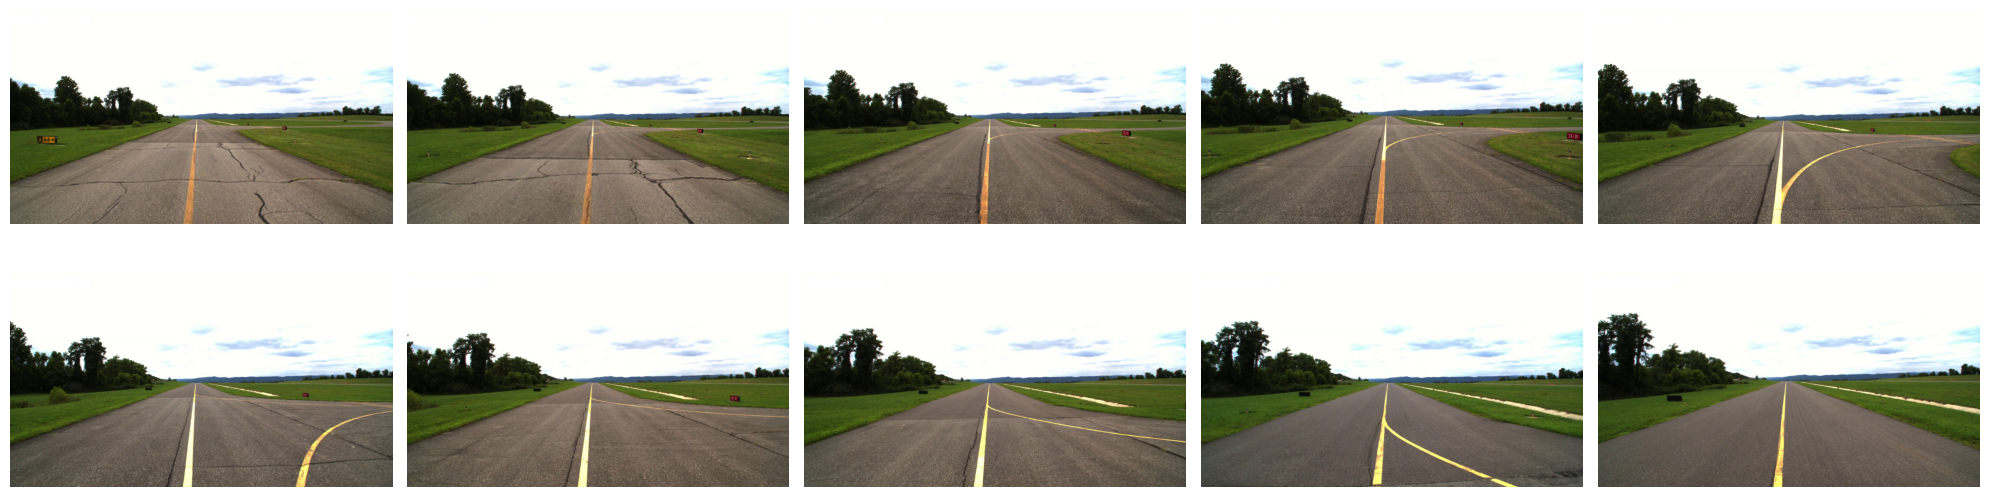

In [4]:
# Visualizer 
gnav.visualize_local_ims()

In [17]:
# Keep only points near the 10 test cameras (R in COLMAP units - tune by eye)
R_keep = 10.0
C = np.array([gnav.images_c[i].projection_center() for i in gnav.im_ids])
d = np.min(np.linalg.norm(gnav.scene_pts[:, None] - C[None], axis=2), axis=1)
near_idx = np.where(d < R_keep)[0]

# RANSAC plane on the trimmed cloud, then map back to full scene_pts indices
pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(gnav.scene_pts[near_idx]))
plane, inl = pcd.segment_plane(distance_threshold=0.001, ransac_n=3, num_iterations=1000)
pts_gnd_idx = near_idx[inl]
print(len(near_idx), 'near pts,', len(pts_gnd_idx), 'ground pts')


51798 near pts, 16874 ground pts


In [18]:
# Using pre_calculated ground plane points - read explanation below 
# pts_gnd_idx = np.load('../datasets/KBCB_params/ground_pts_idxs.npy')
# gnav.pts_gnd_idx = pts_gnd_idx
# Run the ground plane extractor for visualization purposes 
# pts_gnd_idx_test = gnav.get_gnd_pts() 
# Visualize ground plane points 
gnav.visualize_ground_pts(pts_gnd_idx) # UNCOMMENT for visualizations 

In [19]:
# Visualize trimmed cloud (near_idx) with ground points in red
vis = o3d.visualization.Visualizer()
vis.create_window(window_name='Trimmed cloud + GROUND pts')

# Near-camera cloud in its COLMAP colors
near_cloud = o3d.geometry.PointCloud()
near_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[near_idx])
near_cloud.colors = o3d.utility.Vector3dVector(gnav.scene_rgb[near_idx])

# Ground points in red
gnd_cloud = o3d.geometry.PointCloud()
gnd_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[pts_gnd_idx])
gnd_cloud.paint_uniform_color([1.0, 0, 0])

vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=1))
vis.add_geometry(near_cloud)
vis.add_geometry(gnd_cloud)
vis.run()
vis.destroy_window()


In [20]:
# Save April ground plane indices (into April scene_pts) and attach to class
np.save('../datasets/KBCB_params/ground_pts_idxs_april.npy', pts_gnd_idx)
gnav.pts_gnd_idx = pts_gnd_idx